In [1]:
using Pkg
Pkg.activate("..")
using MajoranaPropagation
using Revise
using PauliPropagation
using Plots
using LaTeXStrings
using Measures

  Activating project at `c:\Users\jugro\Desktop\8Sem_ETH\Research Project\Simulations\path\to\project`


In [2]:
#important functions
function expand_tensor(pairs)
    result = [Dict{Int,Any}()]
    for pair in pairs
        new_result = []
        for r in result
            for p in pair
                merged = copy(r)
                merge!(merged, p)
                push!(new_result, merged)
            end
        end
        result = new_result
    end

    return result
end

function to_fock(state, N)
    ups = Int[]
    dns = Int[]

    for (site, spin) in state

        if spin == :updn || spin == :dnup
            push!(ups, site)
            push!(dns, site)

        elseif spin == :up
            push!(ups, site)

        elseif spin == :dn
            push!(dns, site)
        end
    end

    return FockState(N, sort(ups), sort(dns))
end;

In [40]:
#System
is_spinful = true
N_x = 2
N_y = 4
N_spinful_sites = N_x * N_y

t = 1.
U1 = 0
U2 = 2.
U3 = 4.

n_layers = 20
dt = 0.1

min_abs_coeff = 1.e-4
max_unpaired = 4
unpaired_mask = create_unpaired_mask(2 * N_spinful_sites);

topo = rectangletopology(N_x, N_y,periodic=true)

circ_single1 = []
thetas_single1 = []
circ_single2 = []
thetas_single2 = []
circ_single3 = []
thetas_single3 = []

#up hoppings 
for (i, j) in topo
    push!(circ_single1, FermionicGate(:hopup, [i, j]))
    push!(thetas_single1, -t * dt)
    push!(circ_single2, FermionicGate(:hopup, [i, j]))
    push!(thetas_single2, -t * dt)
    push!(circ_single3, FermionicGate(:hopup, [i, j]))
    push!(thetas_single3, -t * dt)
end

#down hoppings 
for (i, j) in topo
    push!(circ_single1, FermionicGate(:hopdn, [i, j]))
    push!(thetas_single1, -t * dt)
    push!(circ_single2, FermionicGate(:hopdn, [i, j]))
    push!(thetas_single2, -t * dt)
    push!(circ_single3, FermionicGate(:hopdn, [i, j]))
    push!(thetas_single3, -t * dt)
end

#on-site repulsion 
for i = 1:N_spinful_sites
    push!(circ_single1, FermionicGate(:nupndn, i))
    push!(thetas_single1, U1 * dt)
    push!(circ_single2, FermionicGate(:nupndn, i))
    push!(thetas_single2, U2 * dt)
    push!(circ_single3, FermionicGate(:nupndn, i))
    push!(thetas_single3, U3 * dt)
end


#construction of initial state from doublon and pairs
site_pairs = [(1,2), (3,5), (4,6), (7,8)]
pairs = [] 

for (s1, s2) in site_pairs
    push!(pairs, [Dict(s1 => :up, s2 => :dn), Dict(s1 => :dn, s2 => :up)])
end

#preparing inital states
states = expand_tensor(pairs)
fock_states = [to_fock(s, N_spinful_sites) for s in states]
initial_state = [fock_states[i] for i in 1:length(fock_states)]
coeffs = [1/4,1/4,1/4,1/4,1/4,1/4,1/4,1/4,1/4,1/4,1/4,1/4,1/4,1/4,1/4,1/4]

@show initial_state;


initial_state = FockState{UInt32}[Fock state with 8 fermions at positions
    ↑: 1, 3, 4, 7
    ↓: 2, 5, 6, 8
, Fock state with 8 fermions at positions
    ↑: 1, 3, 4, 8
    ↓: 2, 5, 6, 7
, Fock state with 8 fermions at positions
    ↑: 1, 3, 6, 7
    ↓: 2, 4, 5, 8
, Fock state with 8 fermions at positions
    ↑: 1, 3, 6, 8
    ↓: 2, 4, 5, 7
, Fock state with 8 fermions at positions
    ↑: 1, 4, 5, 7
    ↓: 2, 3, 6, 8
, Fock state with 8 fermions at positions
    ↑: 1, 4, 5, 8
    ↓: 2, 3, 6, 7
, Fock state with 8 fermions at positions
    ↑: 1, 5, 6, 7
    ↓: 2, 3, 4, 8
, Fock state with 8 fermions at positions
    ↑: 1, 5, 6, 8
    ↓: 2, 3, 4, 7
, Fock state with 8 fermions at positions
    ↑: 2, 3, 4, 7
    ↓: 1, 5, 6, 8
, Fock state with 8 fermions at positions
    ↑: 2, 3, 4, 8
    ↓: 1, 5, 6, 7
, Fock state with 8 fermions at positions
    ↑: 2, 3, 6, 7
    ↓: 1, 4, 5, 8
, Fock state with 8 fermions at positions
    ↑: 2, 3, 6, 8
    ↓: 1, 4, 5, 7
, Fock state with 8 fermions at 

1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20 

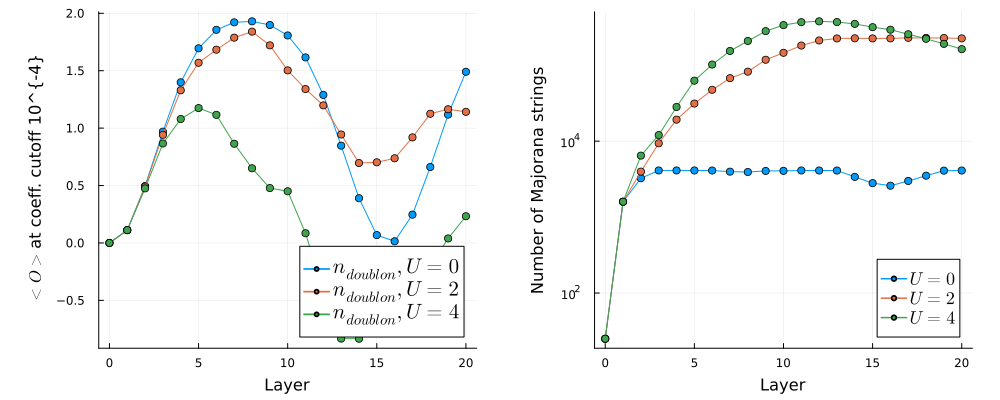

In [41]:
#observables
obs_doubl = MajoranaSum(Float64, N_spinful_sites, is_spinful)
for i=1:N_spinful_sites
    add!(obs_doubl, :nupndn, i)
end
obs_doubl = VectorMajoranaSum(obs_doubl)

obs_doubl1 = deepcopy(obs_doubl)
obs_doubl2 = deepcopy(obs_doubl)
obs_doubl3 = deepcopy(obs_doubl)

res1 = zeros(n_layers+1)
length1 = zeros(n_layers+1)
res2 = zeros(n_layers+1)
length2 = zeros(n_layers+1)
res3 = zeros(n_layers+1)
length3 = zeros(n_layers+1)
res1[1]=overlapwithfock(obs_doubl, initial_state, coeffs)
length1[1] = length(obs_doubl)
res2[1] = overlapwithfock(obs_doubl, initial_state, coeffs)
length2[1] = length(obs_doubl)
res3[1] = overlapwithfock(obs_doubl, initial_state, coeffs)
length3[1] = length(obs_doubl)

#simulation of expectation values
for j = 1:n_layers 
    print("$j ")
    propagate!(circ_single1, obs_doubl1, thetas_single1; min_abs_coeff=min_abs_coeff,max_unpaired=max_unpaired, unpaired_mask=unpaired_mask)
    res1[j+1] = overlapwithfock(obs_doubl1, initial_state, coeffs)
    length1[j+1] = length(obs_doubl1)

    propagate!(circ_single2, obs_doubl2, thetas_single2; min_abs_coeff=min_abs_coeff,max_unpaired=max_unpaired, unpaired_mask=unpaired_mask)
    res2[j+1] = overlapwithfock(obs_doubl2, initial_state, coeffs)
    length2[j+1] = length(obs_doubl2)

    propagate!(circ_single3, obs_doubl3, thetas_single3; min_abs_coeff=min_abs_coeff,max_unpaired=max_unpaired, unpaired_mask=unpaired_mask)
    res3[j+1] = overlapwithfock(obs_doubl3, initial_state, coeffs)
    length3[j+1] = length(obs_doubl3)
end

ev_plot = plot(xlabel = "Layer", ylabel = L"<O>"*"at coeff. cutoff " *"10^{-4}", legend = :bottomright, legend_font_pointsize = 14)
plot!(ev_plot, 0:n_layers, res1, label=L"n_{doublon}, U=0", marker=:circle)
plot!(ev_plot, 0:n_layers, res2, label=L"n_{doublon}, U=2", marker=:circle)
plot!(ev_plot, 0:n_layers, res3, label=L"n_{doublon}, U=4", marker=:circle)
length_plot = plot(xlabel = "Layer",ylabel = "Number of Majorana strings", yscale = :log10, legend = :bottomright,legend_font_pointsize = 12)
plot!(length_plot, 0:n_layers, length1, label=L"U=0", marker=:circle)
plot!(length_plot, 0:n_layers, length2, label=L"U=2", marker=:circle)
plot!(length_plot, 0:n_layers, length3, label=L"U=4", marker=:circle)

plot(ev_plot, length_plot, layout=(1,2), size=(1000,400),left_margin = 10mm, bottom_margin = 5mm, right_margin = 5mm)